This code is authored by Rohieth Raj S

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path


In [8]:
def find_root():
    p = Path.cwd().resolve()
    for d in [p, *p.parents]:
        if (d / "MANIFEST.md").exists():
            return d
    raise FileNotFoundError("Run this from inside the project folder")

BASE_DIR = find_root()
DATA_DIR   = BASE_DIR / "common" / "data_processed"
NODES_FILE = DATA_DIR / "nodes_9.0.csv"
EDGES_FILE = DATA_DIR / "edges_6.0.csv"
OUT_DIR = BASE_DIR / "members" / "rohieth"



1. Millets & Pseudo-Cereals — Top Regional Signatures
  • ragi (grain & flour)             -> North East India Recipes (5.9%), Karnataka (4.3%), South Indian Recipes (3.0%)
  • bajra (grain & flour)            -> Himachal (6.7%), Gujarati Recipes (3.1%), Rajasthani (3.0%)
  • jowar (grain & flour)            -> North Karnataka (21.4%), Sindhi (3.3%), Maharashtrian Recipes (3.3%)
  • foxtail millet                   -> South Indian Recipes (2.7%), Tamil Nadu (2.3%), Chettinad (1.5%)
  • multigrain / other millet flour  -> Gujarati Recipes (4.2%), Maharashtrian Recipes (2.0%), Chettinad (1.5%)
  • barnyard millet                  -> Maharashtrian Recipes (1.3%), South Indian Recipes (1.1%), Tamil Nadu (0.8%)
  • amaranth seeds                   -> North Indian Recipes (0.9%), Karnataka (0.7%), Maharashtrian Recipes (0.7%)
  • buckwheat flour                  -> Gujarati Recipes (1.0%), North Indian Recipes (0.1%)
  • kodo millet                      -> South Indian Recipes (0.4%)
  • sa

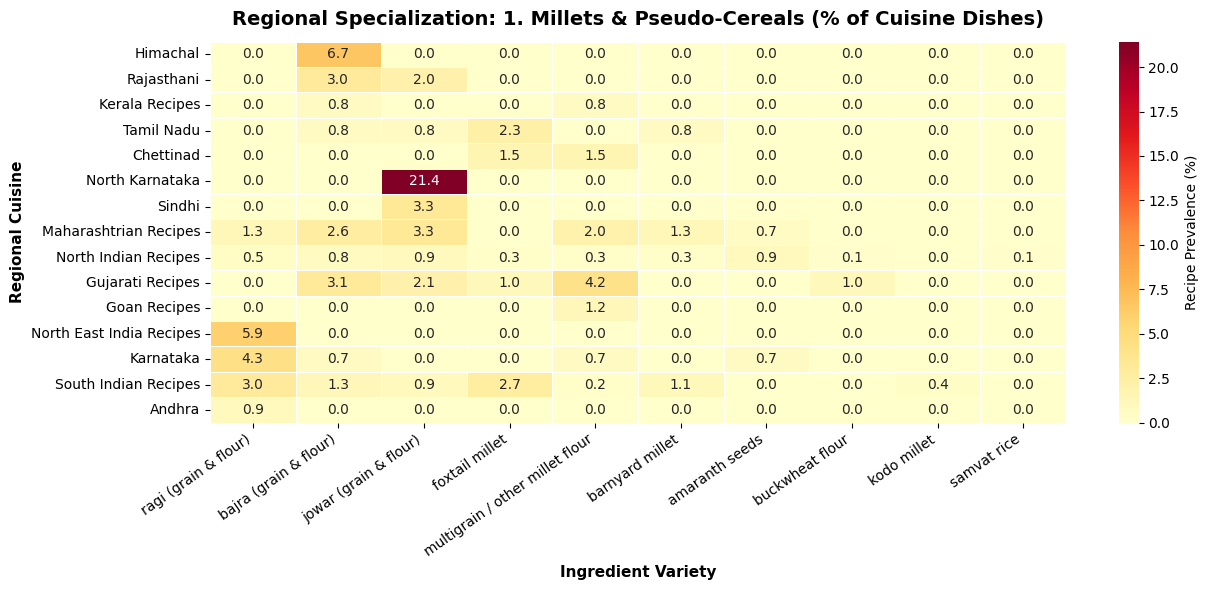


2. Rice Varieties & Flakes — Top Regional Signatures
  • rice                             -> Malabar (36.4%), Coorg (28.6%), Assamese (25.0%)
  • basmati rice                     -> Awadhi (24.2%), Malabar (18.2%), Hyderabadi (15.4%)
  • poha                             -> Malabar (9.1%), Karnataka (8.0%), Konkan (3.1%)
  • puffed rice                      -> Uttar Pradesh (8.3%), Udupi (6.7%), Karnataka (1.4%)
  • matta rice                       -> Udupi (13.3%), Kerala Recipes (3.0%), Goan Recipes (2.4%)
  • brown rice                       -> Udupi (6.7%), Mangalorean (2.2%), Maharashtrian Recipes (1.3%)
  • black rice                       -> North East India Recipes (5.9%), Chettinad (4.6%), South Indian Recipes (0.4%)
  • govind bhog rice                 -> Bengali Recipes (4.0%)
  • seeraga samba rice               -> Tamil Nadu (1.5%), Karnataka (0.7%), South Indian Recipes (0.2%)
  • sona masuri rice                 -> South Indian Recipes (0.2%)
  • jasmine rice            

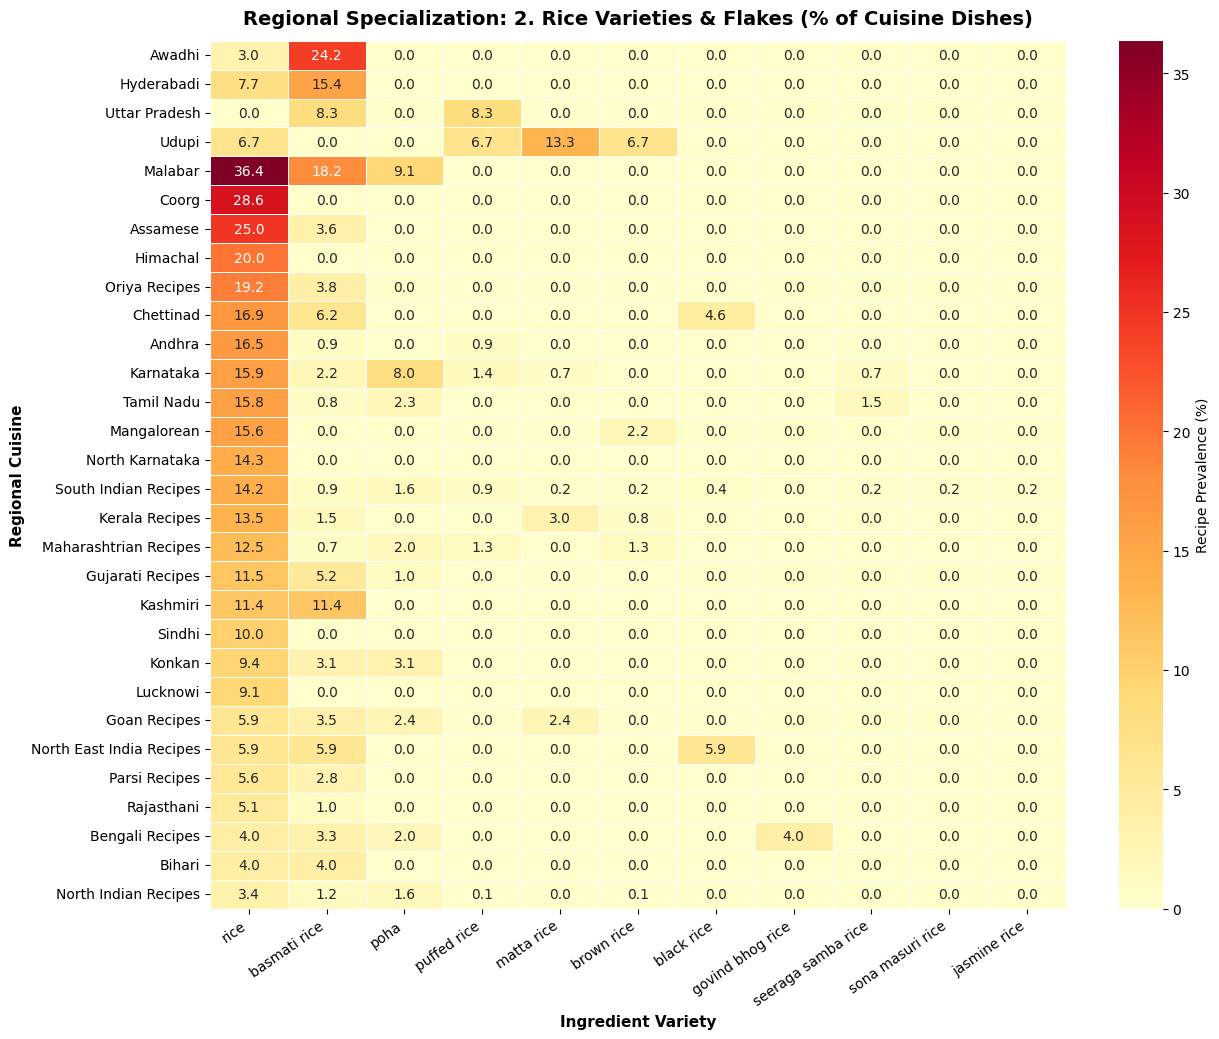


3. Regional & Specialty Masalas — Top Regional Signatures
  • garam masala                     -> Lucknowi (63.6%), Punjabi (59.0%), Awadhi (45.5%)
  • chaat masala powder              -> North Indian Recipes (9.6%), Lucknowi (9.1%), Awadhi (9.1%)
  • sambar powder                    -> Tamil Nadu (11.3%), South Indian Recipes (8.4%), Chettinad (7.7%)
  • panch phoran masala              -> Assamese (32.1%), Oriya Recipes (23.1%), Bengali Recipes (12.7%)
  • maharashtrian goda masala        -> Maharashtrian Recipes (11.2%), North Indian Recipes (0.3%), South Indian Recipes (0.2%)
  • rasam powder                     -> Konkan (3.1%), Karnataka (2.9%), Mangalorean (2.2%)
  • pav bhaji masala                 -> Maharashtrian Recipes (2.0%), Punjabi (1.6%), North Indian Recipes (0.9%)
  • tandoori masala                  -> North Indian Recipes (0.8%)
  • dhansak masala                   -> Parsi Recipes (13.9%)
  • kolhapuri masala                 -> Maharashtrian Recipes (1.3%), North 

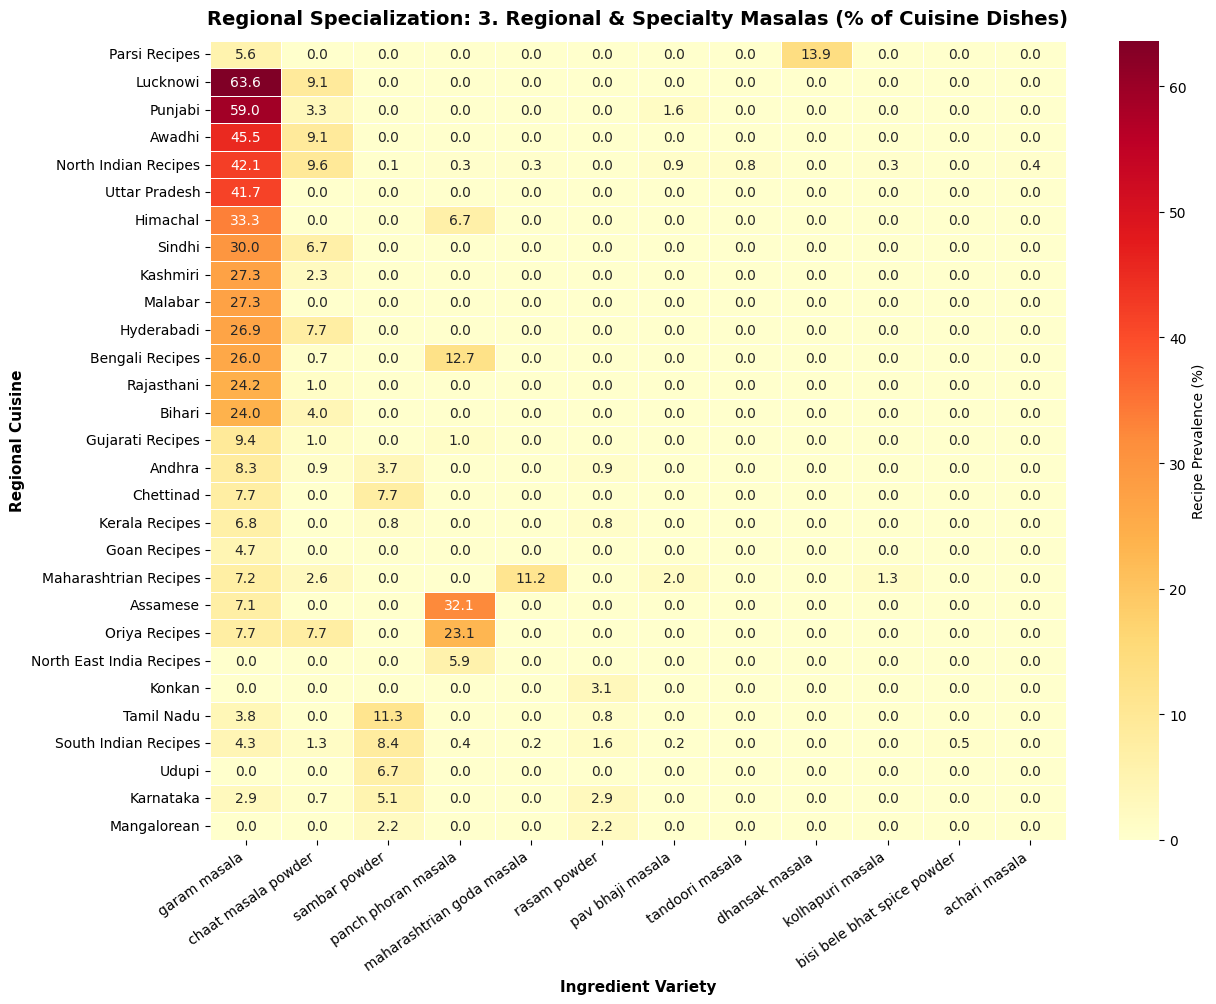


4. Leafy Greens & Culinary Leaves — Top Regional Signatures
  • curry leaves                     -> Andhra (75.2%), Tamil Nadu (74.4%), Kerala Recipes (68.4%)
  • coriander leaves                 -> Uttar Pradesh (58.3%), Lucknowi (54.5%), Awadhi (51.5%)
  • bay leaves                       -> Kashmiri (43.2%), Assamese (42.9%), Himachal (40.0%)
  • methi leaves                     -> Sindhi (16.7%), North Indian Recipes (16.5%), Punjabi (14.8%)
  • mint                             -> Hyderabadi (19.2%), Lucknowi (18.2%), Malabar (18.2%)
  • spinach                          -> North East India Recipes (17.6%), Sindhi (10.0%), Malabar (9.1%)
  • dill leaves                      -> Himachal (6.7%), Karnataka (5.8%), Sindhi (3.3%)
  • drumstick leaves                 -> Tamil Nadu (1.5%), Kerala Recipes (1.5%), South Indian Recipes (1.4%)
  • green amaranth leaves            -> North Karnataka (7.1%), Andhra (3.7%), Chettinad (1.5%)
  • spring onion                     -> North East Indi

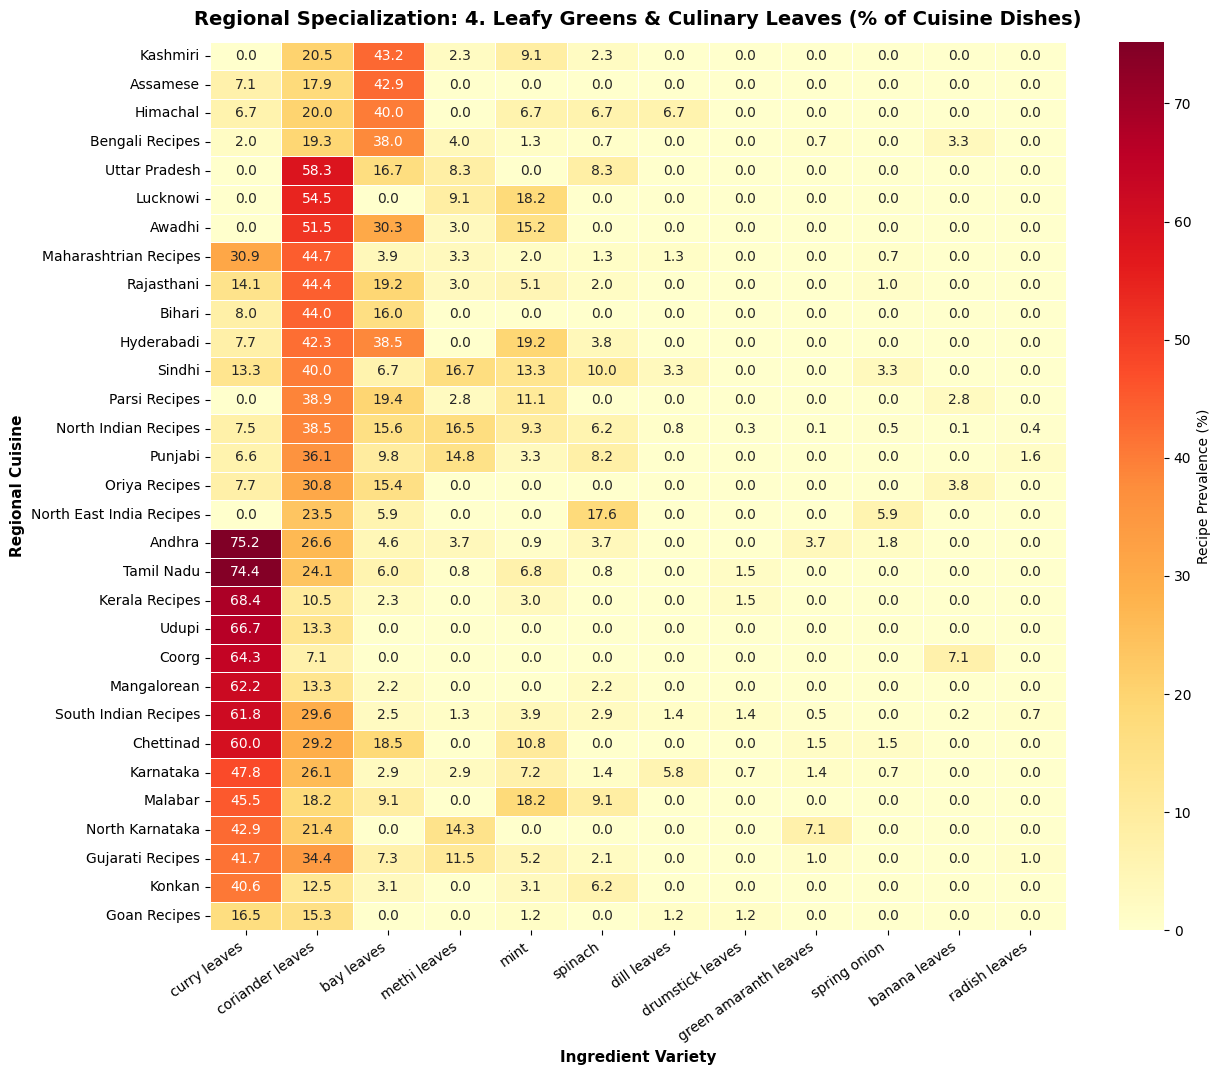


5. Signature Whole & Ground Spices — Top Regional Signatures
  • red chilli                       -> Uttar Pradesh (83.3%), Konkan (78.1%), Sindhi (76.7%)
  • turmeric                         -> Punjabi (77.0%), Uttar Pradesh (75.0%), Rajasthani (70.7%)
  • green chilli                     -> Bihari (72.0%), Lucknowi (63.6%), Sindhi (63.3%)
  • cumin                            -> Uttar Pradesh (75.0%), Sindhi (66.7%), Punjabi (63.9%)
  • mustard seeds                    -> Tamil Nadu (69.2%), Udupi (66.7%), Andhra (62.4%)
  • coriander seeds                  -> Himachal (73.3%), Mangalorean (64.4%), Uttar Pradesh (58.3%)
  • asafoetida                       -> Gujarati Recipes (50.0%), Maharashtrian Recipes (48.7%), Himachal (46.7%)
  • cardamom                         -> Hyderabadi (57.7%), Lucknowi (54.5%), Awadhi (48.5%)
  • cinnamon                         -> Himachal (53.3%), Kashmiri (52.3%), Hyderabadi (42.3%)
  • tamarind                         -> Konkan (59.4%), Udupi (53.3%

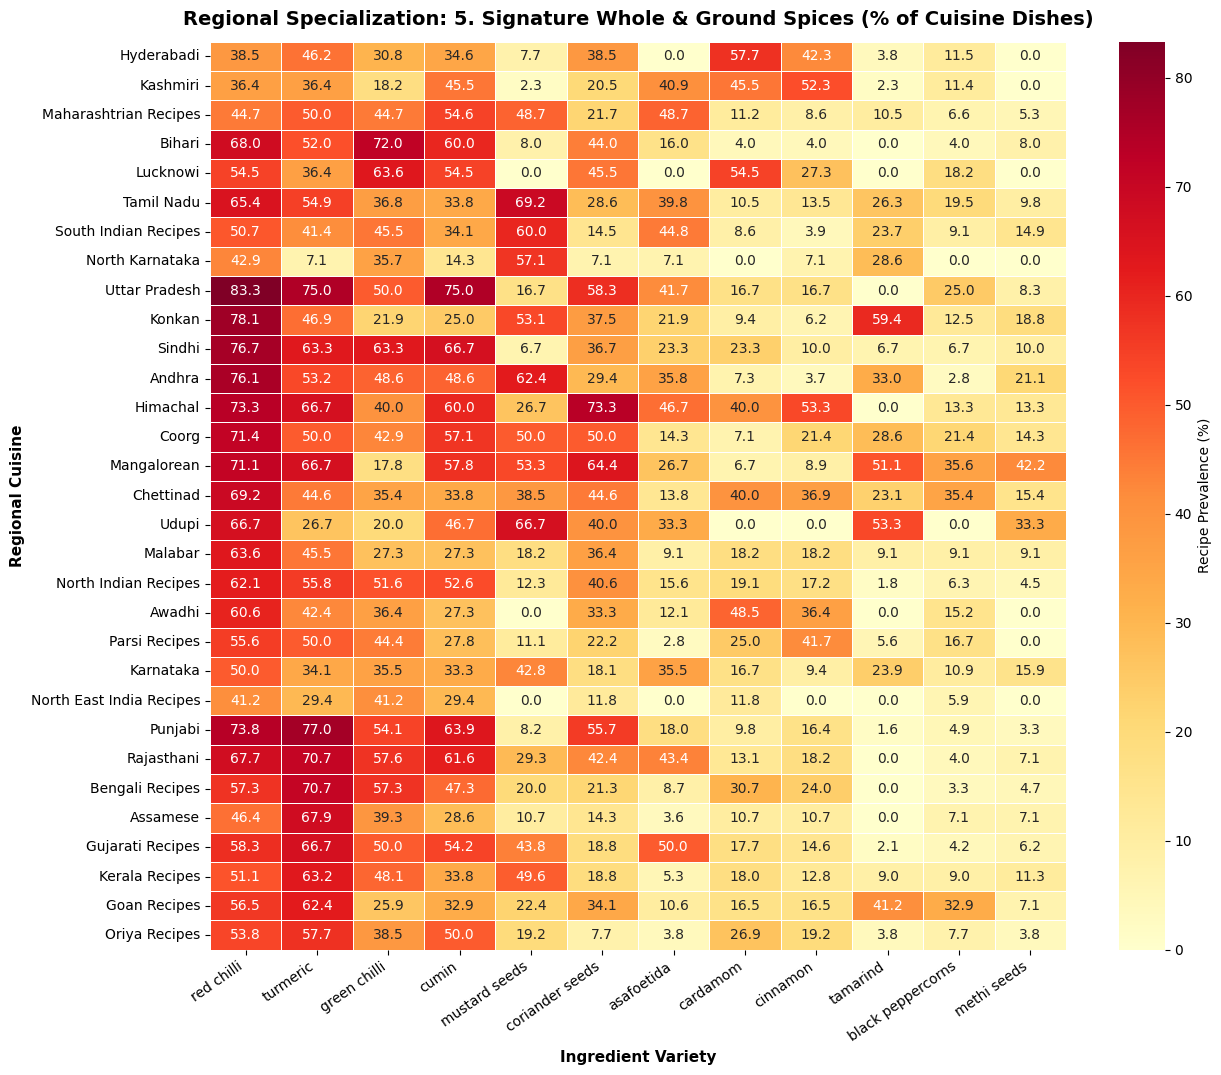

In [9]:
# ==========================================
# 1. LOAD & PREPARE BIPARTITE NETWORK DATA
# ==========================================
nodes_df = pd.read_csv(NODES_FILE)
edges_df = pd.read_csv(EDGES_FILE)

# Clean invisible BOM characters and whitespace in Cuisine names
nodes_df['Cuisine'] = (
    nodes_df['Cuisine']
    .astype(str)
    .str.replace('\ufeff', '', regex=False)
    .str.strip()
)

recipes = nodes_df[nodes_df['Type'] == 'Recipe'].copy()
recipe_cuisine_map = recipes.set_index('Id')['Cuisine'].to_dict()
recipe_label_map = recipes.set_index('Id')['Label'].astype(str).str.lower().to_dict()

# Standardize edge direction: Recipe_Id -> Ingredient
is_source_recipe = edges_df['Source'].isin(recipe_cuisine_map)
e1 = edges_df[is_source_recipe][['Source', 'Target']].rename(
    columns={'Source': 'Recipe_Id', 'Target': 'Ingredient'}
)
e2 = edges_df[~is_source_recipe][['Target', 'Source']].rename(
    columns={'Target': 'Recipe_Id', 'Source': 'Ingredient'}
)
rel_df = pd.concat([e1, e2], ignore_index=True).drop_duplicates()
rel_df['Ingredient'] = rel_df['Ingredient'].astype(str).str.lower().str.strip()
rel_df['Cuisine'] = rel_df['Recipe_Id'].map(recipe_cuisine_map)
rel_df['Recipe_Label'] = rel_df['Recipe_Id'].map(recipe_label_map)

# Filter out generic 'Indian' and cuisines with fewer than MIN_DISHES recipes
MIN_DISHES = 10
cuisine_totals = recipes.groupby('Cuisine')['Id'].nunique()
valid_cuisines = cuisine_totals[
    (cuisine_totals >= MIN_DISHES) & (cuisine_totals.index != 'Indian')
].index.tolist()

rel_df = rel_df[rel_df['Cuisine'].isin(valid_cuisines)].copy()
cuisine_totals = cuisine_totals.loc[valid_cuisines]

# ==========================================
# 2. SMART DISAMBIGUATION FOR 'MILLET FLOUR'
# ==========================================
# Recover specific millet varieties from Recipe Labels when Ingredient == 'millet flour'
expanded_rows = []
for idx, row in rel_df[rel_df['Ingredient'] == 'millet flour'].iterrows():
    lbl = row['Recipe_Label']
    matched = False
    if any(k in lbl for k in ['ragi', 'finger millet', 'nachni', 'kezhvaragu']):
        r = row.copy(); r['Ingredient'] = 'ragi (grain & flour)'; expanded_rows.append(r); matched = True
    if any(k in lbl for k in ['jowar', 'jolada', 'sorghum', 'cholam']):
        r = row.copy(); r['Ingredient'] = 'jowar (grain & flour)'; expanded_rows.append(r); matched = True
    if any(k in lbl for k in ['bajra', 'kambu', 'pearl millet']):
        r = row.copy(); r['Ingredient'] = 'bajra (grain & flour)'; expanded_rows.append(r); matched = True
    if not matched:
        r = row.copy(); r['Ingredient'] = 'multigrain / other millet flour'; expanded_rows.append(r)

# Also map raw 'ragi', 'jowar seeds', 'bajra' into the unified variety names
rel_df['Ingredient'] = rel_df['Ingredient'].replace({
    'ragi': 'ragi (grain & flour)',
    'jowar seeds': 'jowar (grain & flour)',
    'bajra': 'bajra (grain & flour)'
})
rel_df = pd.concat([rel_df[rel_df['Ingredient'] != 'millet flour'], pd.DataFrame(expanded_rows)], ignore_index=True)
rel_df = rel_df.drop_duplicates(subset=['Recipe_Id', 'Ingredient'])

# ==========================================
# 3. DEFINE THE 5 SUB-VARIETY FAMILIES
# ==========================================
ingredient_families = {
    "1. Millets & Pseudo-Cereals": [
        'ragi (grain & flour)', 'bajra (grain & flour)', 'jowar (grain & flour)',
        'foxtail millet', 'barnyard millet', 'kodo millet', 'amaranth seeds',
        'buckwheat flour', 'samvat rice', 'multigrain / other millet flour'
    ],
    "2. Rice Varieties & Flakes": [
        'rice', 'basmati rice', 'poha', 'puffed rice', 'brown rice',
        'matta rice', 'govind bhog rice', 'black rice', 'seeraga samba rice',
        'sona masuri rice', 'jasmine rice'
    ],
    "3. Regional & Specialty Masalas": [
        'garam masala', 'chaat masala powder', 'sambar powder', 'panch phoran masala',
        'maharashtrian goda masala', 'goda masala', 'rasam powder', 'pav bhaji masala',
        'tandoori masala', 'biryani masala', 'achari masala', 'chana masala powder',
        'bisi bele bhat spice powder', 'goan recheado masala', 'reacheado masala',
        'kolhapuri masala', 'malwani masala', 'saoji masala', 'koli masala',
        'bhaja masala', 'vangi bath powder', 'puliodarai powder', 'dhansak masala'
    ],
    "4. Leafy Greens & Culinary Leaves": [
        'coriander leaves', 'curry leaves', 'bay leaves', 'mint', 'methi leaves',
        'spinach', 'spring onion', 'dill leaves', 'drumstick leaves', 'gongura leaves',
        'amaranth leaves', 'green amaranth leaves', 'red amaranth leaves',
        'colocasia leaves', 'bathua leaves', 'banana leaves', 'turmeric leaves',
        'mustard greens', 'agathi keerai', 'radish leaves', 'betel leaves', 'tulsi'
    ],
    "5. Signature Whole & Ground Spices": [
        'red chilli', 'turmeric', 'green chilli', 'cumin', 'mustard seeds',
        'coriander seeds', 'asafoetida', 'cardamom', 'cinnamon', 'tamarind',
        'cloves', 'fennel seeds', 'methi seeds', 'black peppercorns', 'pepper',
        'ajwain', 'amchur', 'saffron', 'kashmiri red chilli', 'kalonji',
        'black cardamom', 'nutmeg', 'kokum', 'star anise', 'mace', 'Mustard',
        'guntur chilli', 'black salt', 'rock salt', 'anardana seeds', 'kachampuli'
    ]
}

# ==========================================
# 4. COMPUTE REGIONAL PREVALENCE & PLOT
# ==========================================
def analyze_and_plot_family(family_name, item_list, top_n_items=12):
    sub_df = rel_df[rel_df['Ingredient'].isin([x.lower() for x in item_list])]
    if sub_df.empty:
        return None
    
    # Keep top N most frequent varieties in this family for visual clarity
    top_varieties = sub_df['Ingredient'].value_counts().head(top_n_items).index.tolist()
    sub_df = sub_df[sub_df['Ingredient'].isin(top_varieties)]
    
    # Count unique recipes per (Cuisine, Ingredient)
    counts = sub_df.groupby(['Cuisine', 'Ingredient'])['Recipe_Id'].nunique().unstack(fill_value=0)
    
    # Normalize by total dishes in each cuisine -> Prevalence (%)
    prevalence = counts.div(cuisine_totals, axis=0).dropna(how='all') * 100
    # Keep only cuisines that use at least one variety in this family
    prevalence = prevalence.loc[(prevalence.sum(axis=1) > 0), top_varieties]
    
    # Sort cuisines by their peak usage for a clean diagonal structure
    max_var = prevalence.idxmax(axis=1)
    max_val = prevalence.max(axis=1)

    # Add helper columns
    prevalence['Max_Var'] = max_var
    prevalence['Max_Val'] = max_val

    prevalence = prevalence.sort_values(by=['Max_Var', 'Max_Val'], ascending=[True, False]).drop(columns=['Max_Var', 'Max_Val'])
    
    # Print top signature region for each variety
    print(f"\n{'='*65}\n{family_name} — Top Regional Signatures\n{'='*65}")
    for col in prevalence.columns:
        top_cuis = prevalence[col].nlargest(3)
        top_str = ", ".join([f"{c} ({v:.1f}%)" for c, v in top_cuis.items() if v > 0])
        print(f"  • {col:32s} -> {top_str}")
        
    # Plot Heatmap
    plt.figure(figsize=(13, max(6, len(prevalence) * 0.35)))
    sns.heatmap(
        prevalence, cmap="YlOrRd", annot=True, fmt=".1f",
        linewidths=0.5, cbar_kws={'label': 'Recipe Prevalence (%)'}
    )
    plt.title(f"Regional Specialization: {family_name} (% of Cuisine Dishes)", fontsize=14, fontweight='bold', pad=12)
    plt.xlabel("Ingredient Variety", fontsize=11, fontweight='bold')
    plt.ylabel("Regional Cuisine", fontsize=11, fontweight='bold')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"{family_name}.png", dpi=300)
    plt.show()
    return prevalence

# Run for all 5 families
family_matrices = {}
for fam_title, fam_items in ingredient_families.items():
    family_matrices[fam_title] = analyze_and_plot_family(fam_title, fam_items, top_n_items=12)
